# MicroGrad: Scalar Autograd Engine Demo

## Objective
This notebook demonstrates the MicroGrad implementation developed
in `src/engine.py` and `src/nn.py`.

We will:
1. Test scalar operations and automatic differentiation.
2. Build a neural network using our own MicroGrad classes.
3. Train the network using gradients computed by our engine.
4. Visualize the training loss and model predictions.

All gradients are computed by our own implementation, without using
PyTorch for automatic differentiation.

In [19]:
import random
import matplotlib.pyplot as plt

from src.engine import Value
from src.nn import MLP

random.seed(42)

print("MicroGrad imports successful!")

MicroGrad imports successful!


## 1. Scalar Operations and Automatic Differentiation

We first create scalar values and combine them using our MicroGrad engine.
Then, we run backpropagation to calculate their gradients using the chain rule.

In [20]:
# Create two scalar values
a = Value(2.0, label="a")
b = Value(3.0, label="b")

# Build a computational graph: c = a*b + a
c = a * b + a

print("a =", a.data)
print("b =", b.data)
print("c =", c.data)

# Calculate gradients
c.backward()

print("dc/da =", a.grad)
print("dc/db =", b.grad)

a = 2.0
b = 3.0
c = 8.0
dc/da = 4.0
dc/db = 2.0


## 2. Activation Functions

MicroGrad supports the `tanh` and `exp` activation/ mathematical operations.
We will test `tanh` and verify that backpropagation computes its gradient.

In [21]:
# Test the tanh activation
x = Value(0.5, label="x")
y = x.tanh()

print("Input x:", x.data)
print("tanh(x):", y.data)

y.backward()

print("Gradient dy/dx:", x.grad)

Input x: 0.5
tanh(x): 0.46211715726000974
Gradient dy/dx: 0.7864477329659274


## 3. Building a Neural Network

We now use our own `Neuron`, `Layer`, and `MLP` classes to construct a neural network.

In [22]:
# Create a neural network with 3 inputs,
# two hidden layers of 4 neurons each, and 1 output
model = MLP(nin=3, nouts=[4, 4, 1])

print("Number of layers:", len(model.layers))
print("Number of parameters:", len(model.parameters()))

Number of layers: 3
Number of parameters: 41


## 4. Training a Neural Network

We train our MLP on a small toy dataset.
The model makes predictions, calculates a loss, and updates its parameters using gradients from MicroGrad.

In [23]:
# Four training examples, each with 3 input features
xs = [
    [Value(2.0), Value(3.0), Value(-1.0)],
    [Value(3.0), Value(-1.0), Value(0.5)],
    [Value(0.5), Value(1.0), Value(1.0)],
    [Value(1.0), Value(1.0), Value(-1.0)],
]

# Target outputs
ys = [Value(1.0), Value(-1.0), Value(-1.0), Value(1.0)]

print("Training examples:", len(xs))
print("Inputs per example:", len(xs[0]))
print("Targets:", [y.data for y in ys])

Training examples: 4
Inputs per example: 3
Targets: [1.0, -1.0, -1.0, 1.0]


In [24]:
# Initialize a fresh model
random.seed(42)
model = MLP(nin=3, nouts=[4, 4, 1])

learning_rate = 0.05
epochs = 100
loss_history = []

for epoch in range(epochs):
    # Forward pass
    predictions = [model(x) for x in xs]

    # Mean squared error loss
    loss = sum(
        [(prediction - target) ** 2 for prediction, target in zip(predictions, ys)],
        Value(0.0)
    ) / len(ys)

    # Reset gradients before backpropagation
    model.zero_grad()

    # Backward pass
    loss.backward()

    # Gradient descent update
    for parameter in model.parameters():
        parameter.data -= learning_rate * parameter.grad

    loss_history.append(loss.data)

print("Initial loss:", round(loss_history[0], 4))
print("Final loss:", round(loss_history[-1], 4))

Initial loss: 1.3076
Final loss: 0.0163


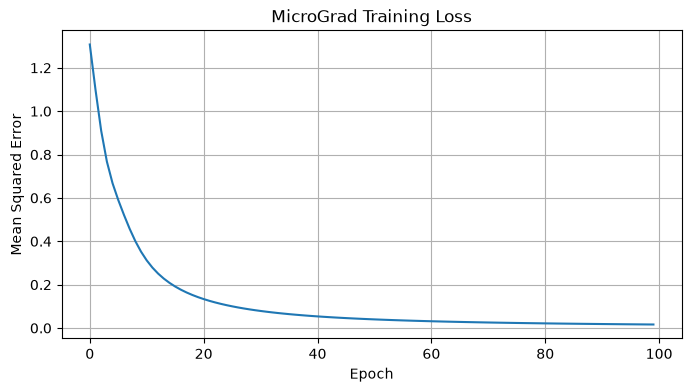

In [25]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("MicroGrad Training Loss")
plt.grid(True)
plt.show()

In [26]:
final_predictions = [model(x) for x in xs]

print("Target\tPrediction")
for target, prediction in zip(ys, final_predictions):
    print(f"{target.data:.3f}\t{prediction.data:.3f}")

Target	Prediction
1.000	0.861
-1.000	-0.917
-1.000	-0.839
1.000	0.890


## 5. Evaluation and Visualization

We compare the target values with the predictions produced by the trained network.
This helps us see how closely the model fits the training data.

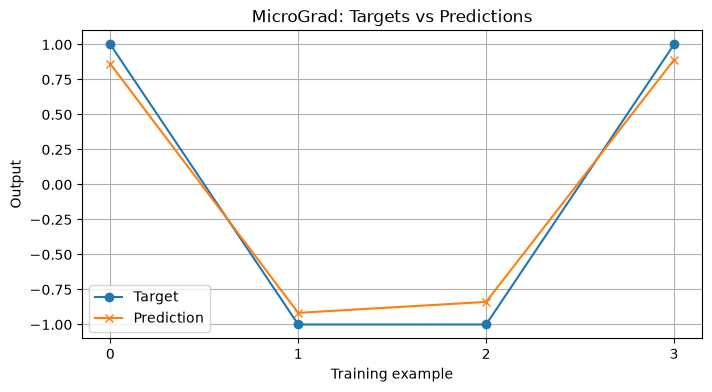

In [27]:
final_predictions = [model(x) for x in xs]

targets = [y.data for y in ys]
predicted_values = [p.data for p in final_predictions]

plt.figure(figsize=(8, 4))
indices = range(len(targets))

plt.plot(indices, targets, marker="o", label="Target")
plt.plot(indices, predicted_values, marker="x", label="Prediction")

plt.xlabel("Training example")
plt.ylabel("Output")
plt.title("MicroGrad: Targets vs Predictions")
plt.xticks(list(indices))
plt.legend()
plt.grid(True)
plt.show()

## 6. Conclusion

In this notebook, we demonstrated the MicroGrad implementation from scratch.

- Scalar operations build a computational graph.
- Backpropagation computes gradients using the chain rule.
- The custom MLP performs forward passes through its layers.
- Gradient descent updates the network parameters.
- Training loss and predictions are visualized to evaluate learning.

All gradients were computed using our custom MicroGrad engine, without PyTorch autograd.